In [1]:
#----------------------------------------------------------------
#IMPORTATION DES PACKAGES NECESSAIRES
#----------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from itertools import count
import heapq
from heapq import heappush, heappop
import math


# 1) Calculer l'entropie du texte sur le lien suivant : https://ecogestion.univ-paris13.fr/parcours-big-data-analyse-et-business-intelligence/

In [2]:
# -------------------------------------------------------------
# CALCUL DE L'ENTROPIE DU TEXTE
# -------------------------------------------------------------


# =======================
# TEXTE FOURNI
# =======================
texte = """ ORGANISATION
L’année de M1 comprend deux semestres composés de 4 UE fondamentales pour le premier et de 5 UE de spécialisation au deuxième semestre.
Les étudiants en parcours Big Data suivent des UE spécifiques. En M2, l’encadrement pédagogique est assuré par des enseignants universitaires et par des professionnels.
La réalisation de nombreux dossiers et travaux en groupe permettent aux étudiants d’affiner leurs compétences (écrit, présentation orale, synthèse, projet…).

En M2, les cours se déroulent de mi-septembre à fin février, la deuxième partie de l’année est consacrée au stage (3 mois minimum, 6 mois maximum).

OBJECTIFS PEDAGOGIQUES
« Au-delà de l’aspect statistique, il faudra être capable de visualiser, communiquer et utiliser les données.
Savoir accéder à, comprendre et transmettre les conclusions tirées des données: Ces talents vont être extrêmement importants » (Hal Varian, chef économiste de Google)

La prolifération des objets connectés engendre une immense quantité de données structurées ou non et la tendance va se poursuivre.
L’objectif du master est de former les étudiants aux métiers des données massives (big data) et de leur traitement / analyse.
Répondant aux attentes des professionnels, le master propose aux étudiants un enseignement marquant autour notamment des outils liés aux big data
(statistiques, outils d’analyses, machine learning, business intelligence….) et de l’économétrie.

Les étudiants seront capables d’analyser ces données massives, afin de dégager des indicateurs utiles aux décideurs et de permettre une prise de décision efficace par d’autres services de l’entreprise.
Il s’agit donc de former des personnes qui seront à l’interface entre les scientifiques des données massives (data scientists) et la prise de décisions stratégiques (marketing, production….).
Ils joueront donc un rôle transverse dans l’entreprise.

PRE-REQUIS
Le titulaire aura une bonne maîtrise de l’outil rédactionnel.
Il doit aussi manier efficacement les outils informatiques et de présentation orale (type Power Point).
La maîtrise de l’anglais est nécessaire. Des connaissances de base en économétrie sont requises.

les compétences développées :
• Analyser et décrypter les données massives à l’aide d’outils statistiques et économétriques pour proposer une analyse stratégique.
• Gérer des grands volumes de données
• Acquérir la capacité de mise en forme des données et présenter les données via des formats accessibles
• Interagir avec les scientifiques des données via la connaissance des problématiques et enjeux de base liés au big data.
• Maîtriser les logiciels de base du big data.
• Comprendre les architectures informatiques et contraintes des data scientists
• Comprendre les principaux algorithmes utilisés dans le big data.
• Etre capable de travailler en équipe
• Organisation, rigueur, capacité rédactionnelle
• Connaissance de l’écosystème et des principaux acteurs qui produisent / gèrent / travaillent la data

PUBLIC VISE
– Etudiants venant d’un parcours économie ou gestion en M1
– Etudiants venant d’un parcours économie ou gestion ou d’un parcours data en M2

MOBILITE INTERNATIONALE
Echange possible au cours de l’année de M1 sous réserve d’accord du responsable sur les cours suivis à l’étranger.
Le stage de M2 peut être effectué à l’étranger.

AUTRES PARTENAIRES
Nous travaillons avec les entreprises Akabi et Alteryx qui proposent des interventions dans l’année.
Nous avons également mis en place un partenariat avec MyJobGlasses afin d’améliorer l’insertion des étudiants. """


# -------------------------------------------------------------
# 1) ENTROPIE SUR LES CARACTERES
# -------------------------------------------------------------

# Compter la fréquence de chaque caractère
car_counts = Counter(texte)
total_chars = sum(car_counts.values())

# Probabilités de chaque caractère
car_probs = [count / total_chars for count in car_counts.values()]

# Entropie Shannon sur les caractères (H = -Σ p log2 p)
H_char = -sum(p * math.log2(p) for p in car_probs if p > 0)

# Perplexité = 2^H
perplexity_char = 2 ** H_char

# Taille de l’alphabet (nombre de caractères différents)
alphabet_size = len(car_counts)

# Entropie maximale possible = log2(|Alphabet|)
H_char_max = math.log2(alphabet_size)

# Entropie normalisée = H / Hmax
H_char_norm = H_char / H_char_max





In [3]:
# -------------------------------------------------------------
# 2) ENTROPIE CONDITIONNELLE (BIGRAMMES)
# -------------------------------------------------------------

# Compter les paires de caractères (bigrammes)
bigram_counts = Counter([texte[i:i+2] for i in range(len(texte)-1)])

cond_entropy = 0.0
for c in car_counts:
    # total des caractères qui suivent un caractère donné
    total_follow = sum(bigram_counts[c+next_c] for next_c in set(texte) if c+next_c in bigram_counts)
    if total_follow == 0:
        continue

    # probas conditionnelles P(next_c | c)
    probs_follow = [bigram_counts[c+next_c]/total_follow for next_c in set(texte) if c+next_c in bigram_counts]

    # H(Y|X=c)
    H_c = -sum(p * math.log2(p) for p in probs_follow if p > 0)

    # pondérer par la fréquence de c
    cond_entropy += (car_counts[c]/total_chars) * H_c

# perplexité conditionnelle
perplexity_cond = 2 ** cond_entropy




In [4]:
# -------------------------------------------------------------
# 3) ENTROPIE SUR LES MOTS
# -------------------------------------------------------------

# Tokenisation basique des mots (nettoyage ponctuation + minuscule)
words = [w.strip(".,:;!?()«»…").lower() for w in texte.split() if w.strip() != ""]

# Comptage des mots
word_counts = Counter(words)
total_words = sum(word_counts.values())

# Probabilités des mots
word_probs = [count / total_words for count in word_counts.values()]

# Entropie Shannon sur les mots
H_word = -sum(p * math.log2(p) for p in word_probs if p > 0)

# Perplexité sur les mots
perplexity_word = 2 ** H_word

# Taille du vocabulaire
vocab_size = len(word_counts)

# Entropie max possible sur vocabulaire
H_word_max = math.log2(vocab_size)

# Normalisation
H_word_norm = H_word / H_word_max




In [5]:
# -------------------------------------------------------------
# 4) METTRE LES RESULTATS DANS UN TABLEAU
# -------------------------------------------------------------

df_results = pd.DataFrame([
    {"Type":"Caractère","Entropie (bits)":H_char,"Perplexité":perplexity_char,"Alphabet/Vocab":alphabet_size,"Normalisée":H_char_norm},
    {"Type":"Caractère conditionnel","Entropie (bits)":cond_entropy,"Perplexité":perplexity_cond,"Alphabet/Vocab":alphabet_size,"Normalisée":cond_entropy/H_char},
    {"Type":"Mot","Entropie (bits)":H_word,"Perplexité":perplexity_word,"Alphabet/Vocab":vocab_size,"Normalisée":H_word_norm},
])

print(df_results)

                     Type  Entropie (bits)  Perplexité  Alphabet/Vocab  \
0               Caractère         4.576351   23.857176              73   
1  Caractère conditionnel         3.158275    8.927615              73   
2                     Mot         7.376619  166.181822             273   

   Normalisée  
0    0.739335  
1    0.690129  
2    0.911509  


# 2) Déterminer le codage de Huffman , sa longeur moyenne ainsi que le taux de compression. Afficher le dictionnaire

In [6]:
# Calculons la fréquence de chaque caractère
df_freq_chars = pd.DataFrame(
    [{"Caractère": c, "Fréquence": n, "Probabilité": n/total_chars} for c, n in car_counts.items()]
).sort_values(by="Fréquence", ascending=False).reset_index(drop=True)

print("=== Fréquences des caractères ===")
print(df_freq_chars.head(20))


=== Fréquences des caractères ===
   Caractère  Fréquence  Probabilité
0                   485     0.136928
1          e        395     0.111519
2          s        281     0.079334
3          n        221     0.062394
4          a        215     0.060700
5          t        214     0.060418
6          i        194     0.054771
7          r        185     0.052230
8          o        143     0.040373
9          d        133     0.037549
10         u        124     0.035008
11         l        108     0.030491
12         c         93     0.026256
13         é         81     0.022868
14         m         73     0.020610
15         p         70     0.019763
16        \n         47     0.013269
17         g         37     0.010446
18         v         31     0.008752
19         f         29     0.008187


In [7]:
# -------------------------------------------------------------
# 1) CONSTRUCTION DE L'ARBRE DE HUFFMAN (heap)
#    - Pas de fonctions: on code tout en direct
# -------------------------------------------------------------
heap = []
u = count()  # identifiant pour départager les égalités

# Feuilles: (freq, id, symbole)
for ch, freq in car_counts.items():
    heappush(heap, (freq, next(u), ch))

# Cas limite si un seul symbole: code "0"
if len(heap) == 1:
    root = heappop(heap)[2]
else:
    # Fusion des deux plus petites fréquences jusqu'à la racine
    while len(heap) > 1:
        f1, _, n1 = heappop(heap)
        f2, _, n2 = heappop(heap)
        node = {"left": n1, "right": n2}
        heappush(heap, (f1 + f2, next(u), node))
    root = heappop(heap)[2]


In [8]:

# -------------------------------------------------------------
# 2) PARCOURS POUR EXTRAIRE LES CODES (gauche='0', droite='1')
# -------------------------------------------------------------
codes = {}                   # dict final: caractère -> code binaire
stack = [(root, "")]         # pile (noeud, code_accumulé)

while stack:
    node, code = stack.pop()
    if isinstance(node, str):
        codes[node] = code if code != "" else "0"  # sécurité si 1 seul symbole
    else:
        stack.append((node["right"], code + "1"))
        stack.append((node["left"],  code + "0"))


In [9]:

# -------------------------------------------------------------
# 3) LONGUEUR MOYENNE + TAILLES + TAUX COMPRESSION
# -------------------------------------------------------------
A = len(car_counts)  # taille alphabet
prob_par_char = {c: car_counts[c]/total_chars for c in car_counts}

# Longueur moyenne en bits/symbole: Σ p_i * |code_i|
L_moy = sum(prob_par_char[c] * len(codes[c]) for c in car_counts)

# Taille compressée totale (bits): Σ freq_i * |code_i|
bits_compresse = sum(car_counts[c] * len(codes[c]) for c in car_counts)

# Références de comparaison
bits_fixes_par_sym = math.ceil(math.log2(A)) if A > 1 else 1
bits_ref_fixe = bits_fixes_par_sym * total_chars
bits_ref_8 = 8 * total_chars  # approx 1 octet/char (UTF-8 réel variable)

taux_vs_fixe = bits_compresse / bits_ref_fixe if bits_ref_fixe > 0 else 1.0
taux_vs_8    = bits_compresse / bits_ref_8    if bits_ref_8    > 0 else 1.0
gain_vs_fixe = 1 - taux_vs_fixe
gain_vs_8    = 1 - taux_vs_8



In [10]:
# -------------------------------------------------------------
# 4) DICTIONNAIRE LISIBLE (trié par fréquence décroissante)
# -------------------------------------------------------------
lignes = []
for c, n in sorted(car_counts.items(), key=lambda kv: kv[1], reverse=True):
    # représentation propre des espaces/sauts de ligne sans fonction
    rep = "<ESPACE>" if c == " " else ("<SAUT_DE_LIGNE>" if c == "\n" else c)
    lignes.append({
        "Caractère": rep,
        "Fréquence": n,
        "Probabilité": round(n/total_chars, 6),
        "Code": codes[c],
        "Longueur": len(codes[c]),
    })

df_codes = pd.DataFrame(lignes)



In [11]:
# -------------------------------------------------------------
# 5) SORTIES
# -------------------------------------------------------------
print("\n---- RÉSUMÉ HUFFMAN ----")
print(f"Nombre de caractères                     : {sum(car_counts.values())}")
print(f"Taille alphabet                          : {A}")
print(f"Longueur moyenne (bits/symbole)          : {L_moy:.4f}")
print(f"Taille compressée totale (bits)          : {bits_compresse}")
print(f"[Réf codage fixe optimal] bits/symbole   : {bits_fixes_par_sym}")
print(f"Taux de compression vs FIXE              : {taux_vs_fixe:.4f}  (gain = {gain_vs_fixe:.2%})")
print(f"[Réf 8 bits par caractère]               : 8 bits/symbole")
print(f"Taux de compression vs 8 BITS            : {taux_vs_8:.4f}   (gain = {gain_vs_8:.2%})")

print("\n---- Dictionnaire Huffman (Top 50 par fréquence) ----")
print(df_codes.head(50).to_string(index=False))




---- RÉSUMÉ HUFFMAN ----
Nombre de caractères                     : 3542
Taille alphabet                          : 73
Longueur moyenne (bits/symbole)          : 4.5946
Taille compressée totale (bits)          : 16274
[Réf codage fixe optimal] bits/symbole   : 7
Taux de compression vs FIXE              : 0.6564  (gain = 34.36%)
[Réf 8 bits par caractère]               : 8 bits/symbole
Taux de compression vs 8 BITS            : 0.5743   (gain = 42.57%)

---- Dictionnaire Huffman (Top 50 par fréquence) ----
      Caractère  Fréquence  Probabilité       Code  Longueur
       <ESPACE>        485     0.136928        101         3
              e        395     0.111519        010         3
              s        281     0.079334       1110         4
              n        221     0.062394       1001         4
              a        215     0.060700       1000         4
              t        214     0.060418       0111         4
              i        194     0.054771       0011         4


In [12]:
# ---------------------------------------------------------------
# 0) ARBRE DE HUFFMAN SOUS FORME D'OBJETS Node
#    - Même construction que plus haut (heap + compteur pour les égalités)
#    - Utilisé pour l'aperçu ASCII et le dessin matplotlib
# ---------------------------------------------------------------

class Node:
    def __init__(self, id, freq, char=None, left=None, right=None):
        self.id = id          # identifiant unique (positions du dessin)
        self.freq = freq      # fréquence cumulée du sous-arbre
        self.char = char      # caractère (feuilles uniquement)
        self.left = left      # fils gauche (bit 0)
        self.right = right    # fils droit (bit 1)


def build_huffman_tree(texte):
    freqs = Counter(texte)
    if not freqs:
        return None

    uid = count()
    heap = []
    for ch, freq in freqs.items():
        i = next(uid)
        heappush(heap, (freq, i, Node(i, freq, char=ch)))

    while len(heap) > 1:
        f1, _, n1 = heappop(heap)
        f2, _, n2 = heappop(heap)
        i = next(uid)
        heappush(heap, (f1 + f2, i, Node(i, f1 + f2, left=n1, right=n2)))

    return heappop(heap)[2]


In [13]:
# ---------------------------------------------------------------
# 1) Générer un APERÇU ASCII de l'arbre (itératif, sans def)
#    - Convention: gauche=0, droite=1
#    - On affiche: ◦ [freq] pour nœuds internes, • 'x' [freq] pour feuilles
# ---------------------------------------------------------------

print("\n==== ARBRE HUFFMAN (ASCII, aperçu) ====")

# Utiliser la fonction build_huffman_tree sur la variable texte
root = build_huffman_tree(texte)

if root is None:
    print("(Arbre vide)")
else:
    # pile pour parcours (node, prefix_string)
    stack = [(root, "")]
    ascii_lines = []
    while stack:
        node, pref = stack.pop()
        if node.left is None and node.right is None:
            # feuille
            ch = "\\n" if node.char == "\n" else ("<ESPACE>" if node.char == " " else node.char)
            ascii_lines.append(f"{pref}• '{ch}' [{node.freq}]")
        else:
            # interne
            ascii_lines.append(f"{pref}◦ [{node.freq}]")
            # On empile d'abord la droite, puis la gauche (ordre d'affichage lisible avec .pop())
            if node.right is not None:
                stack.append((node.right, pref + "  1→ "))
            if node.left is not None:
                stack.append((node.left,  pref + "  0→ "))

    # Affichage
    max_lines = 200
    for i, line in enumerate(ascii_lines[:max_lines], 1):
        print(line)
    if len(ascii_lines) > max_lines:
        print(f"... ({len(ascii_lines) - max_lines} lignes supplémentaires)")



==== ARBRE HUFFMAN (ASCII, aperçu) ====
◦ [3542]
  0→ ◦ [1544]
  0→   0→ ◦ [726]
  0→   0→   0→ ◦ [347]
  0→   0→   0→   0→ ◦ [162]
  0→   0→   0→   0→   0→ • 'é' [81]
  0→   0→   0→   0→   1→ ◦ [81]
  0→   0→   0→   0→   1→   0→ ◦ [39]
  0→   0→   0→   0→   1→   0→   0→ • ',' [19]
  0→   0→   0→   0→   1→   0→   1→ ◦ [20]
  0→   0→   0→   0→   1→   0→   1→   0→ • 'M' [10]
  0→   0→   0→   0→   1→   0→   1→   1→ • '•' [10]
  0→   0→   0→   0→   1→   1→ ◦ [42]
  0→   0→   0→   0→   1→   1→   0→ • 'E' [21]
  0→   0→   0→   0→   1→   1→   1→ ◦ [21]
  0→   0→   0→   0→   1→   1→   1→   0→ ◦ [10]
  0→   0→   0→   0→   1→   1→   1→   0→   0→ • 'j' [5]
  0→   0→   0→   0→   1→   1→   1→   0→   1→ ◦ [5]
  0→   0→   0→   0→   1→   1→   1→   0→   1→   0→ ◦ [2]
  0→   0→   0→   0→   1→   1→   1→   0→   1→   0→   0→ • 'ô' [1]
  0→   0→   0→   0→   1→   1→   1→   0→   1→   0→   1→ • 'w' [1]
  0→   0→   0→   0→   1→   1→   1→   0→   1→   1→ • '1' [3]
  0→   0→   0→   0→   1→   1→   1→   1→ • 'y' [1


# 3) REPRESENTATION DE L'ARBRE DE HUFFMAN

In [14]:

# ---------------------------------------------------------------
# 1) Calcul des positions (in-order) pour placement sur le plan
#    - Objectif: éviter les croisements, espacer horizontalement
#    - Sans def: on code un parcours itératif in-order
# ---------------------------------------------------------------

positions = {}  # {node_id: (x, y)} ; y = -profondeur pour dessiner vers le bas
x_cursor = 0
stack = []
node = root
depth = 0

# Assigner un id aux nœuds si manquant (sécurité)
# On refait un passage DFS rapide pour ajouter 'id' manquants
if root is not None:
    st = [root]
    # Besoin d'un générateur d'identifiant unique s'il n'est pas déjà présent dans les objets Node
    # Pour des raisons de simplicité, nous supposons que le nœud a un "id" ou nous utilisons l'identité de l'objet.
    # Si le nœud n'a pas d'ID, nous devrions modifier la classe du nœud ou générer des ID ici.
    # D'après les cellules précédentes (Czz9UvRCj-PN, ykoGCbMe9IMQ), le nœud *a un "id".
    # Cette boucle de réaffectation est donc probablement inutile si l'arbre est construit correctement.
    # Cependant, si la structure des nœuds était modifiée, nous aurions besoin d'un moyen robuste.
    # Supposons que Node ait un 'id' comme dans les précédentes exécutions réussies.
    # La tentative du code original d'ajouter 'id' en utilisant get('id', None) et next(uid) était défectueuse
    # car `uid` n'est pas défini dans la portée de cette cellule.
    # Suppression de cette partie potentiellement problématique de l'assignation de l'ID.

    pass # En supposant que les objets Node de build_huffman_tree ont déjà des ID uniques

# Parcours in-order itératif : aller à gauche, visiter, aller à droite
# Réinitialisation du nœud et de la profondeur pour la traversée dans l'ordre
node = root
depth = 0
stack = [] # Effacer la pile

while node is not None or stack:
    while node is not None:
        stack.append((node, depth))
        node = node.left
        depth += 1
    node, depth = stack.pop()
    positions[node.id] = (x_cursor, -depth)
    x_cursor += 1
    node = node.right
    depth += 1


In [15]:

# ---------------------------------------------------------------
# 2) Récupération des arêtes (parent -> enfant) + étiquette 0/1
# ---------------------------------------------------------------

edges = []  # liste de tuples (parent_node, child_node, "0"/"1")
if root is not None:
    st = [root]
    while st:
        n = st.pop()
        if n.left is not None:
            edges.append((n, n.left, "0"))
            st.append(n.left)
        if n.right is not None:
            edges.append((n, n.right, "1"))
            st.append(n.right)



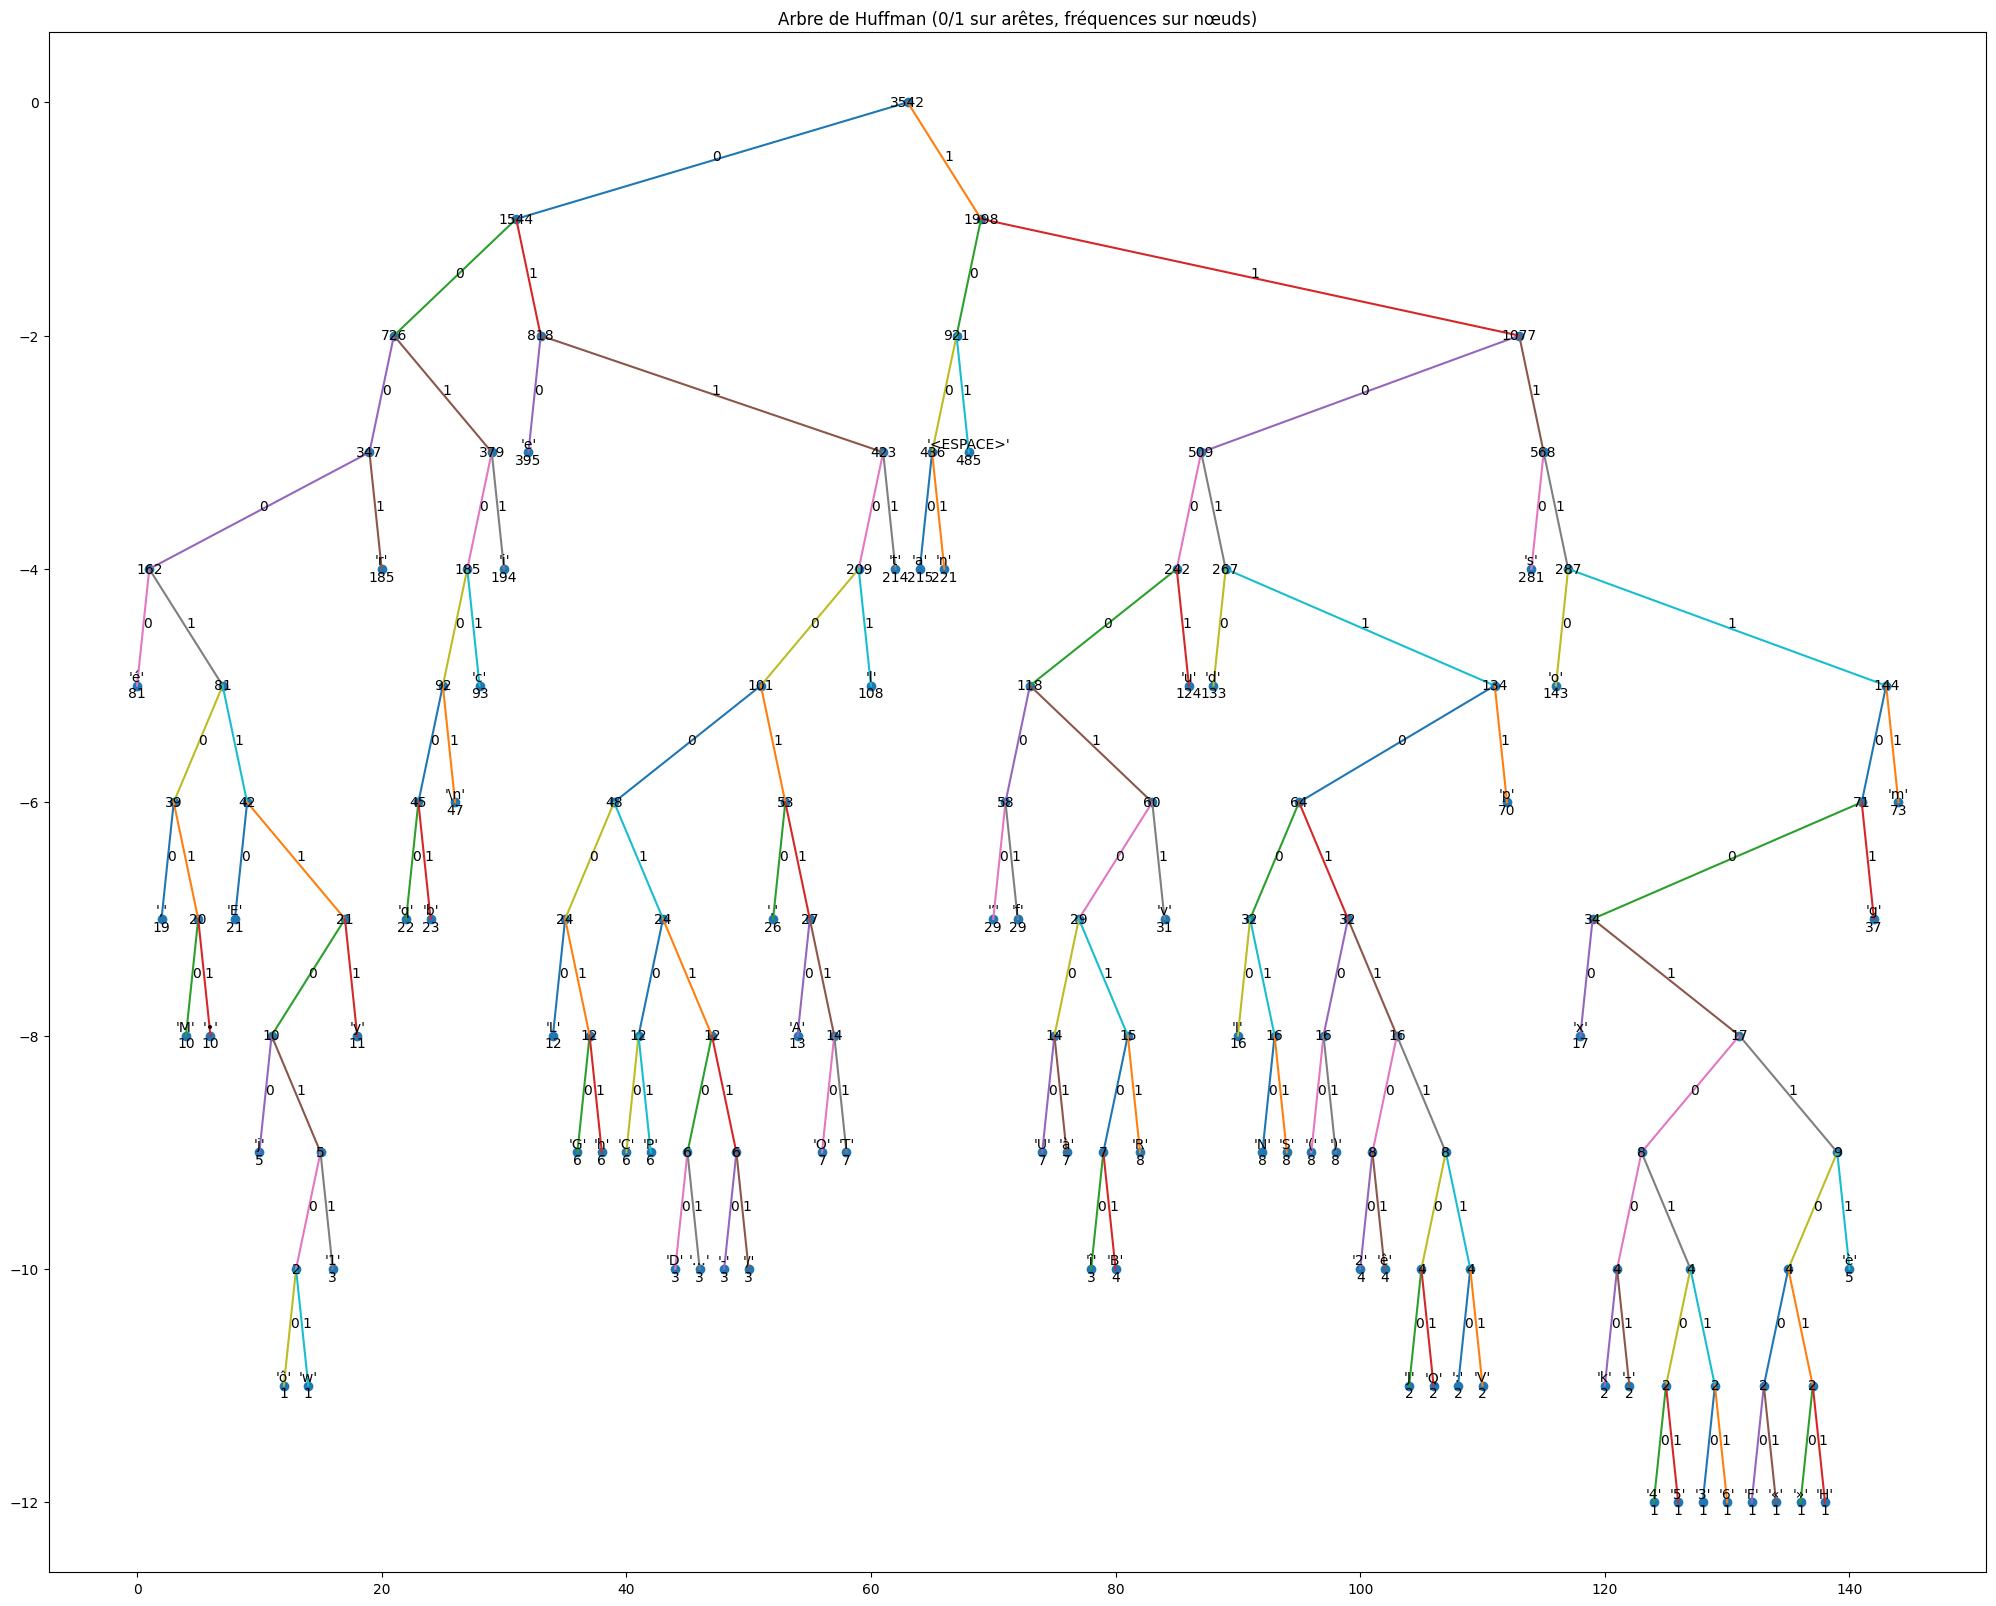

In [16]:
# ---------------------------------------------------------------
# 3) DESSIN matplotlib
#    - Une seule figure
#    - Pas de styles ni couleurs imposés (consigne)
#    - Arêtes avec labels 0/1 ; nœuds avec fréquences (et char pour feuilles)
# ---------------------------------------------------------------

plt.figure(figsize=(25, 20)) # Taille de l'image

# tracer les arêtes
for parent, child, bit in edges:
    x1, y1 = positions[parent.id]
    x2, y2 = positions[child.id]
    plt.plot([x1, x2], [y1, y2])             # segment parent->enfant
    xm, ym = (x1 + x2) / 2.0, (y1 + y2) / 2.0
    plt.text(xm, ym, bit)                    # étiquette 0/1 au milieu

# tracer les nœuds (un seul scatter global)
# Collecter les nœuds de manière robuste à partir des bords et de la racine
nodes_in_edges = set([p for p,_,_ in edges] + [c for _,c,_ in edges])
nodes = nodes_in_edges if nodes_in_edges else ({root} if root else set())

xs = [positions[n.id][0] for n in nodes] if nodes else []
ys = [positions[n.id][1] for n in nodes] if nodes else []
if xs and ys:
    plt.scatter(xs, ys)

# annotations (fréquences, + caractère pour feuilles)
visited = set()
stack = [root] if root is not None else []
while stack:
    n = stack.pop()
    # Vérifier si n est un objet Node avant d'accéder aux attributs
    if not isinstance(n, Node) or n.id in visited:
        continue
    visited.add(n.id)
    x, y = positions[n.id]
    if n.left is None and n.right is None:
        ch = "\\n" if n.char == "\n" else ("<ESPACE>" if n.char == " " else n.char)
        label = f"'{ch}'\n{n.freq}"
    else:
        label = f"{n.freq}"
    plt.text(x, y, label, ha="center", va="center")
    if n.right is not None:
        stack.append(n.right)
    if n.left is not None:
        stack.append(n.left)



# Affichage de l'Arbre d'Huffman
plt.title("Arbre de Huffman (0/1 sur arêtes, fréquences sur nœuds)")
plt.axis("on")
plt.show()